In [2]:
import scipy.integrate as int
import matplotlib.pyplot as plt
import numpy as np

In [37]:
#We want to test the difference between activation functions and the way the dynamics work

tau = 0.5
self_weight = 0
bias = 1

def linear(x):
    return x

def quadratic (x):
    return np.pow(x,2)

def exponential (x):
    return np.exp(x)

nonlinearity = quadratic

def preNonlinearity(t, x):
    return (-x + self_weight*nonlinearity(x) + bias)*(1/tau)

def postNonlinearity(t, y):
    return (-y + nonlinearity(self_weight*y + bias))*(1/tau)

t_span = (0,1)
y_0 = [0]

pre_result = int.solve_ivp(preNonlinearity,t_span,y_0,rtol=1e-6,atol=1e-6)
post_result = int.solve_ivp(postNonlinearity,t_span,y_0,rtol=1e-6,atol=1e-6)

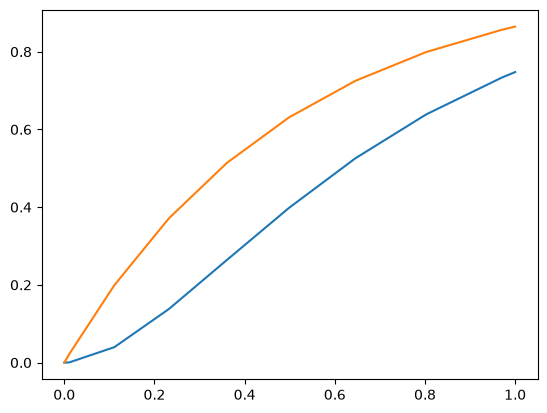

In [38]:
plt.plot(pre_result.t,nonlinearity(pre_result.y[0]))
plt.plot(post_result.t,post_result.y[0])

Text(0.5, 1.0, 'Pre-vs-Post-Nonlinearity Dynamics Comparison')

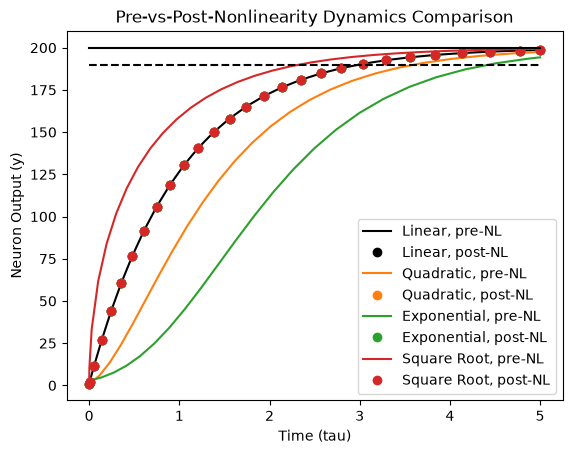

In [79]:
#Iterate over nonlinearities and show the differences between equations

nls = [lambda x: x,
       lambda x: np.pow(x,2),
       lambda x: np.exp(x),
       lambda x: np.sqrt(x)]
inls = [lambda x: x,
        lambda x: np.sqrt(x),
        lambda x: np.log(x),
        lambda x: np.pow(x,2)]
colors = ['k','C1','C2','C3']
self_weight = 0
tau = 1
target = float(200)
y_0 = np.asarray([1],dtype=float)
t_span = (0,5)

for i in range(len(nls)):
    nl = nls[i]
    bias = inls[i](target)
    def preNonlinearity(t, x):
        return (-x + self_weight*nl(x) + bias)*(1/tau)

    def postNonlinearity(t, y):
        return (-y + nl(self_weight*y + bias))*(1/tau)

    pre_result = int.solve_ivp(preNonlinearity,t_span,y_0,rtol=1e-7,atol=1e-7)
    post_result = int.solve_ivp(postNonlinearity,t_span,y_0,rtol=1e-7,atol=1e-7)

    plt.plot(pre_result.t,nl(pre_result.y[0]),color=colors[i],linestyle='-')
    plt.plot(post_result.t,post_result.y[0],color=colors[i],linestyle='',marker='o')

plt.plot(t_span,[target,target],'k-')
plt.plot(t_span,[target*0.95,target*0.95],'k--')
plt.legend(('Linear, pre-NL','Linear, post-NL',
            'Quadratic, pre-NL','Quadratic, post-NL',
            'Exponential, pre-NL','Exponential, post-NL',
            'Square Root, pre-NL','Square Root, post-NL'))
plt.xlabel('Time (tau)')
plt.ylabel('Neuron Output (y)')
plt.title('Pre-vs-Post-Nonlinearity Dynamics Comparison')